# 4a. 5-Fold Cross-Validation & Kalibrasi INT8 TFLite (Representative Dataset Citra Asli)
### Minimasi Accuracy Drop Float32 -> INT8 Menggunakan Citra Asli Non-Augmentasi

Notebook ini mengacu pada **4c** (5-Fold Stratified Chick-Level CV, tanpa threshold tuning, `DEFAULT_THRESHOLD = 0.50`),
dengan perbaikan pada **tahap kuantisasi INT8 (Metode 1)**:
- **`representative_dataset` dari Citra Asli**: Kalibrasi skala min-max INT8 menggunakan seluruh citra asli `train_idx` (tanpa rotasi/fill abu-abu atau jitter warna) + *horizontal flip*, sehingga distribusi aktivasi sesuai dengan citra uji murni.
- **Artefak Model**: Disimpan terpisah ke `PP2/model/cv_folds_4a` agar mudah dibandingkan langsung dengan hasil notebook 4c.


## Langkah 0: Import Library & Konfigurasi Reproduktifitas

In [1]:
import os
import sys
import pathlib
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, ImageEnhance

import tensorflow as tf
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_fscore_support,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    matthews_corrcoef,
    balanced_accuracy_score,
)

# Kunci deterministik random seed untuk reproduksibilitas
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Versi TensorFlow :", tf.__version__)
print("GPU Tersedia     :", len(tf.config.list_physical_devices("GPU")))

2026-11-25 17:51:01.041961: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-25 17:51:01.066227: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-25 17:51:01.273162: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-25 17:51:01.273215: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-25 17:51:01.318068: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

2026-11-25 17:51:02.311048: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

Versi TensorFlow : 2.15.1
GPU Tersedia     : 0


## Langkah 1: Konfigurasi Path, Parameter Model, & Pemuatan Citra Mentah (Chick-Level)
Memuat seluruh 31 ekor anak ayam mentah (16 Female, 15 Male) dari `PP2/data/doc` dengan ekstraksi ROI bentangan sayap utuh (`160x160`).

In [2]:
# Menentukan root direktori proyek PP2 secara otomatis dan portabel
cwd = pathlib.Path.cwd().resolve()
if (cwd / "PP2" / "data").exists():
    PP2_DIR = cwd / "PP2"
elif (cwd / "data").exists():
    PP2_DIR = cwd
elif (cwd.parent / "data").exists():
    PP2_DIR = cwd.parent
else:
    PP2_DIR = cwd
    for p in [cwd] + list(cwd.parents):
        if (p / "PP2" / "data").exists():
            PP2_DIR = p / "PP2"
            break
        elif (p / "data").exists():
            PP2_DIR = p
            break

DATA_RAW_DIR = PP2_DIR / "data" / "doc"
MODEL_OUTPUT_DIR = PP2_DIR / "model"
CV_MODEL_DIR = MODEL_OUTPUT_DIR / "cv_folds_4a"
CV_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Path Pretrained Model Unggas (Domain Adaptation opsional seperti 4b)
PRETRAINED_SEXING_MODEL = MODEL_OUTPUT_DIR / "mobilenetv2_sexing_float32.keras"

# Konfigurasi Model NPU-Friendly (MobileNetV2 alpha=0.35 - 160x160x3)
IMG_SIZE = 160
IMG_SHAPE = (IMG_SIZE, IMG_SIZE, 3)
ALPHA = 0.35
BATCH_SIZE = 16
EPOCHS = 25
N_SPLITS = 5
SAMPLES_PER_TRAIN_SUBJECT = 40
DEFAULT_THRESHOLD = 0.50

# Urutan kelas WAJIB: index 0 = 'Female' (Betina), index 1 = 'Male' (Jantan)
CLASS_NAMES = ["Female", "Male"]
CLASS_LABELS_ID = {0: "Class 0: Betina (Female)", 1: "Class 1: Jantan (Male)"}

print(f"Direktori Proyek PP2     : {PP2_DIR.resolve()}")
print(f"Dataset Mentah DOC       : {DATA_RAW_DIR.resolve()}")
print(f"Output Model CV          : {CV_MODEL_DIR.resolve()}")
print(f"Pretrained Model Unggas  : {'TERSEDIA' if PRETRAINED_SEXING_MODEL.exists() else 'TIDAK DITEMUKAN (Gunakan ImageNet)'}")
print(f"Threshold Keputusan      : {DEFAULT_THRESHOLD:.2f} (Default / Tanpa Tuning)")

def get_chick_bounding_box(img: Image.Image):
    w, h = img.size
    tw = 240
    th = max(1, int(tw * h / w))
    thumb = img.resize((tw, th), resample=Image.BILINEAR)
    arr = np.array(thumb, dtype=np.float32)
    r, g, b = arr[:, :, 0], arr[:, :, 1], arr[:, :, 2]
    chick_mask = (r > 60) & (g > 50) & (r + g > 1.8 * b + 10)
    if np.sum(chick_mask) > 100:
        ys, xs = np.where(chick_mask)
        min_x = np.percentile(xs, 1) / tw
        max_x = np.percentile(xs, 99) / tw
        min_y = np.percentile(ys, 1) / th
        max_y = np.percentile(ys, 99) / th
        cx = (min_x + max_x) / 2.0
        cy = (min_y + max_y) / 2.0
        span = max(max_x - min_x, max_y - min_y) * 1.25
        return cx, cy, span
    return 0.50, (0.35 if h > w else 0.50), 0.85

def extract_full_wing_roi(img: Image.Image, cx_ratio, cy_ratio, span_ratio):
    w, h = img.size
    min_dim = min(w, h)
    crop_size = int(min_dim * max(0.70, min(1.0, span_ratio)))
    cx = int(cx_ratio * w)
    cy = int(cy_ratio * h)
    left = max(0, min(w - crop_size, cx - (crop_size // 2)))
    top = max(0, min(h - crop_size, cy - (crop_size // 2)))
    cropped = img.crop((left, top, left + crop_size, top + crop_size))
    return cropped.resize((IMG_SIZE, IMG_SIZE), resample=Image.LANCZOS)

# Muat semua subjek unik
subjects_images = []
subjects_labels = []
subjects_names = []

for label_idx, cls in enumerate(CLASS_NAMES):
    cls_dir = DATA_RAW_DIR / cls
    files = sorted([f for f in cls_dir.glob("*.jpg")])
    for f in files:
        with Image.open(f) as im:
            im_trans = ImageOps.exif_transpose(im).convert("RGB")
            cx, cy, span = get_chick_bounding_box(im_trans)
            base_roi = extract_full_wing_roi(im_trans, cx, cy, span)
            subjects_images.append(base_roi)
            subjects_labels.append(label_idx)
            subjects_names.append(f.name)

subjects_labels = np.array(subjects_labels)
print(f"\n[INFO] Berhasil memuat {len(subjects_images)} subjek unik:")
print(f"  - Female: {np.sum(subjects_labels == 0)} ekor")
print(f"  - Male  : {np.sum(subjects_labels == 1)} ekor")

Direktori Proyek PP2     : /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2
Dataset Mentah DOC       : /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2/data/doc
Output Model CV          : /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2/model/cv_folds_4a
Pretrained Model Unggas  : TIDAK DITEMUKAN (Gunakan ImageNet)
Threshold Keputusan      : 0.50 (Default / Tanpa Tuning)

[INFO] Berhasil memuat 31 subjek unik:
  - Female: 16 ekor
  - Male  : 15 ekor


## Langkah 2: Pipeline Augmentasi Dinamis (On-The-Fly per Fold) & Visualisasi Sampel
Data dinormalisasi ke rentang `[-1.0, 1.0]` sesuai spesifikasi MobileNetV2. Augmentasi hanya diterapkan pada *training fold*, sedangkan *validation/test fold* menggunakan citra murni tanpa augmentasi.

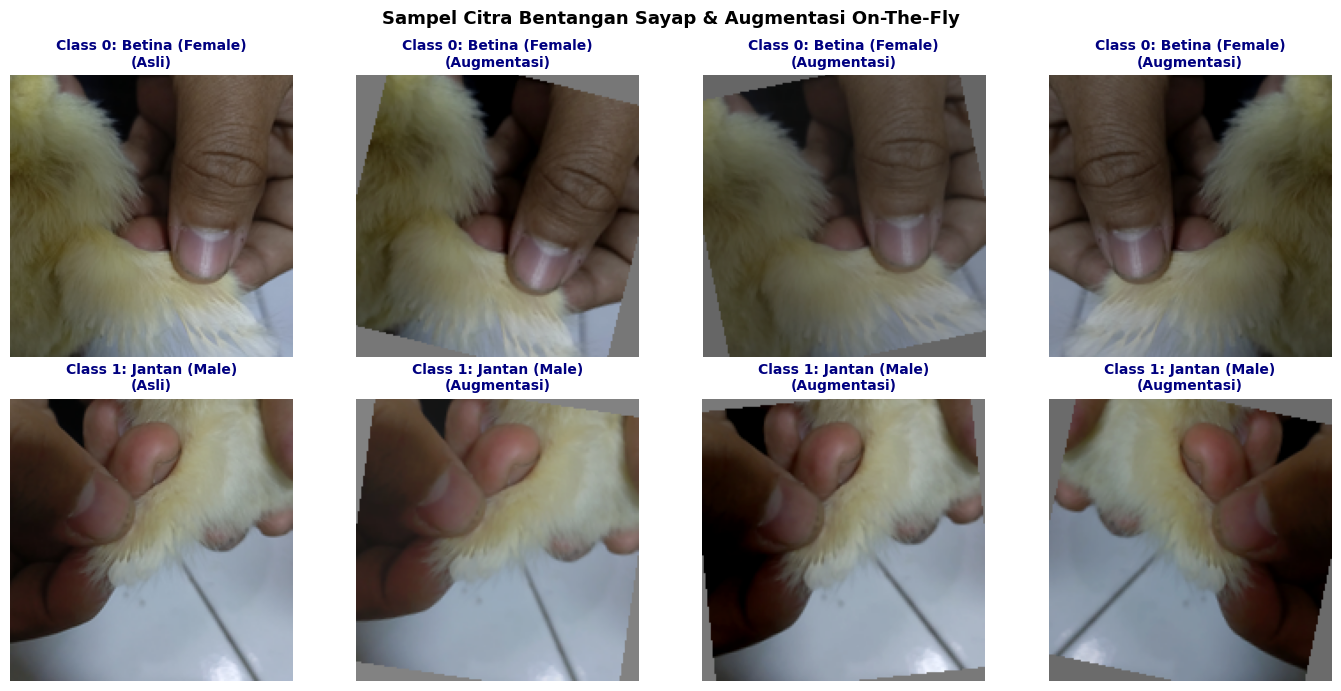

In [3]:
def augment_single_image(img: Image.Image) -> Image.Image:
    # 1. Flip horizontal
    if random.random() < 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
    # 2. Rotasi halus
    angle = random.uniform(-15.0, 15.0)
    img = img.rotate(angle, resample=Image.BILINEAR, expand=False, fillcolor=(128, 128, 128))
    # 3. Kecerahan (Brightness)
    img = ImageEnhance.Brightness(img).enhance(random.uniform(0.80, 1.20))
    # 4. Saturasi Warna (Color)
    img = ImageEnhance.Color(img).enhance(random.uniform(0.75, 1.25))
    # 5. Kontras
    img = ImageEnhance.Contrast(img).enhance(random.uniform(0.85, 1.20))
    return img

def generate_fold_data(train_indices, val_indices, samples_per_train_subject=SAMPLES_PER_TRAIN_SUBJECT):
    X_train, y_train = [], []
    X_val, y_val = [], []

    for idx in train_indices:
        base_img = subjects_images[idx]
        lbl = subjects_labels[idx]
        X_train.append(np.array(base_img, dtype=np.float32) / 127.5 - 1.0)
        y_train.append(lbl)
        for _ in range(samples_per_train_subject - 1):
            aug = augment_single_image(base_img.copy())
            X_train.append(np.array(aug, dtype=np.float32) / 127.5 - 1.0)
            y_train.append(lbl)

    for idx in val_indices:
        base_img = subjects_images[idx]
        lbl = subjects_labels[idx]
        X_val.append(np.array(base_img, dtype=np.float32) / 127.5 - 1.0)
        y_val.append(lbl)

    X_train = np.array(X_train, dtype=np.float32)
    y_train = np.array(y_train, dtype=np.int32)
    X_val = np.array(X_val, dtype=np.float32)
    y_val = np.array(y_val, dtype=np.int32)

    # Acak urutan data training agar batch seimbang
    perm = np.random.permutation(len(X_train))
    return X_train[perm], y_train[perm], X_val, y_val

# Visualisasi 8 sampel hasil augmentasi dari subjek pertama Female & Male
plt.figure(figsize=(14, 7))
sample_indices = [0, 0, 0, 0, len(subjects_images) - 1, len(subjects_images) - 1, len(subjects_images) - 1, len(subjects_images) - 1]
for i, s_idx in enumerate(sample_indices):
    ax = plt.subplot(2, 4, i + 1)
    aug_img = subjects_images[s_idx] if i in (0, 4) else augment_single_image(subjects_images[s_idx].copy())
    plt.imshow(aug_img)
    lbl_idx = int(subjects_labels[s_idx])
    tag = "Asli" if i in (0, 4) else "Augmentasi"
    plt.title(f"{CLASS_LABELS_ID[lbl_idx]}\n({tag})", fontsize=10, fontweight="bold", color="navy")
    plt.axis("off")
plt.suptitle("Sampel Citra Bentangan Sayap & Augmentasi On-The-Fly", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## Langkah 3: Arsitektur MobileNetV2 dengan Backbone Beku & Regularisasi Kuat
Menggunakan arsitektur yang sama dengan notebook **4b**:
- **MobileNetV2 (`alpha=0.35`, `160x160x3`)** dengan bobot ImageNet (atau transfer bobot unggas jika tersedia) dan `base_model.trainable = False`.
- **Dropout `0.50`** + **L2 Weight Decay (`1e-3`)** pada classification head.

In [4]:
def build_npu_mobilenetv2_doc(input_shape=IMG_SHAPE, alpha=ALPHA, num_classes=len(CLASS_NAMES), verbose=False):
    inputs = tf.keras.Input(shape=input_shape, name="input_image")

    base_model = tf.keras.applications.MobileNetV2(
        input_shape=input_shape,
        alpha=alpha,
        include_top=False,
        weights="imagenet",
    )

    if PRETRAINED_SEXING_MODEL.exists():
        try:
            temp_model = tf.keras.models.load_model(PRETRAINED_SEXING_MODEL)
            nested_backbone = None
            for l in temp_model.layers:
                if isinstance(l, tf.keras.Model) or "mobilenetv2" in l.name.lower():
                    nested_backbone = l
                    break
            if nested_backbone is not None:
                base_model.set_weights(nested_backbone.get_weights())
                if verbose:
                    print(f"[SUCCESS] Transfer bobot dari '{nested_backbone.name}' berhasil.")
        except Exception as e:
            if verbose:
                print(f"[WARN] Transfer bobot gagal ({e}), fallback ke ImageNet.")

    base_model.trainable = False

    x = base_model(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = tf.keras.layers.Dropout(0.50, name="dropout_anti_overfitting")(x)
    outputs = tf.keras.layers.Dense(
        num_classes,
        activation="softmax",
        kernel_regularizer=tf.keras.regularizers.l2(1e-3),
        name="doc_classification_head",
    )(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="mobilenetv2_doc_npu")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )
    return model

# Verifikasi ringkasan arsitektur
sample_model = build_npu_mobilenetv2_doc(verbose=True)
sample_model.summary()
del sample_model
tf.keras.backend.clear_session()

Model: "mobilenetv2_doc_npu"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_image (InputLayer)    [(None, 160, 160, 3)]     0         
                                                                 
 mobilenetv2_0.35_160 (Func  (None, 5, 5, 1280)        410208    
 tional)                                                         
                                                                 
 global_avg_pool (GlobalAve  (None, 1280)              0         
 ragePooling2D)                                                  
                                                                 
 dropout_anti_overfitting (  (None, 1280)              0         
 Dropout)                                                        
                                                                 
 doc_classification_head (D  (None, 2)                 2562      
 ense)                                         

## Langkah 4: Eksekusi 5-Fold CV, Kalibrasi INT8 (Citra Asli), & Evaluasi Float32 vs INT8
Perbedaan utama dari 4c: `representative_dataset_gen` memakai **citra asli `train_idx` + horizontal flip** (tanpa distorsi rotasi/jitter warna) agar rentang aktivasi INT8 terkalibrasi akurat.


In [5]:
def convert_fold_to_int8_tflite(keras_model, X_rep, tflite_path):
    @tf.function(input_signature=[tf.TensorSpec(shape=[1, IMG_SIZE, IMG_SIZE, 3], dtype=tf.float32)])
    def static_inference_fn(x):
        return keras_model(x, training=False)

    concrete_func = static_inference_fn.get_concrete_function()

    def representative_dataset_gen():
        num_samples = min(150, len(X_rep))
        indices = np.linspace(0, len(X_rep) - 1, num=num_samples, dtype=int)
        for idx in indices:
            yield [np.expand_dims(X_rep[idx], axis=0)]

    converter = tf.lite.TFLiteConverter.from_concrete_functions([concrete_func])
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_dataset_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8

    tflite_bytes = converter.convert()
    with open(tflite_path, "wb") as f:
        f.write(tflite_bytes)
    return len(tflite_bytes) / 1024.0

def evaluate_int8_tflite(tflite_path, X_val_norm):
    interpreter = tf.lite.Interpreter(model_path=str(tflite_path))
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    in_scale, in_zero_point = input_details["quantization"]
    out_scale, out_zero_point = output_details["quantization"]

    probs_list = []
    for i in range(len(X_val_norm)):
        # X_val_norm sudah berada pada rentang [-1.0, 1.0]
        img_int8 = np.clip(np.round(X_val_norm[i] / in_scale + in_zero_point), -128, 127).astype(np.int8)
        img_int8 = np.expand_dims(img_int8, axis=0)

        interpreter.set_tensor(input_details["index"], img_int8)
        interpreter.invoke()
        output_int8 = interpreter.get_tensor(output_details["index"])[0]

        prob = (output_int8.astype(np.float32) - out_zero_point) * out_scale
        prob = np.clip(prob, 0.0, 1.0)
        if prob.sum() > 0:
            prob = prob / prob.sum()
        probs_list.append(prob)

    return np.array(probs_list, dtype=np.float32)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

fold_histories = []
fold_metrics_f32 = []
fold_metrics_int8 = []
fold_sizes_f32_kb = []
fold_sizes_int8_kb = []

all_val_trues = []
all_val_subject_names = []
all_val_probs_f32 = []
all_val_preds_f32 = []
all_val_probs_int8 = []
all_val_preds_int8 = []

best_fold_idx = -1
best_fold_acc_int8 = -1.0
last_fold_X_val = None
last_fold_y_val = None
last_fold_names = None
last_fold_model = None

print("=" * 80)
print(f"  MEMULAI {N_SPLITS}-FOLD STRATIFIED CROSS-VALIDATION (FLOAT32 -> INT8 TFLITE)")
print("=" * 80)

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(subjects_images, subjects_labels)):
    fold_num = fold_idx + 1
    test_chicks = [subjects_names[i] for i in val_idx]
    print(f"\n>>> [FOLD {fold_num}/{N_SPLITS}] Train: {len(train_idx)} ekor | Test: {len(val_idx)} ekor -> {test_chicks}")

    X_tr, y_tr, X_va, y_va = generate_fold_data(train_idx, val_idx, samples_per_train_subject=SAMPLES_PER_TRAIN_SUBJECT)

    classes_unique = np.unique(y_tr)
    weights = compute_class_weight(class_weight="balanced", classes=classes_unique, y=y_tr)
    class_weights_dict = {int(c): float(w) for c, w in zip(classes_unique, weights)}

    tf.keras.backend.clear_session()
    fold_model = build_npu_mobilenetv2_doc()

    callbacks_list = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=0),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=0),
    ]

    history = fold_model.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights_dict,
        verbose=0,
        callbacks=callbacks_list,
    )
    fold_histories.append(history.history)

    # 1. Evaluasi Float32 (Threshold Default 0.50)
    probs_f32 = fold_model.predict(X_va, verbose=0)
    preds_f32 = (probs_f32[:, 1] >= DEFAULT_THRESHOLD).astype(int)
    acc_f32 = accuracy_score(y_va, preds_f32)
    f1_f32 = f1_score(y_va, preds_f32, average="macro", zero_division=0)

    # Simpan model Float32 fold
    keras_fold_path = CV_MODEL_DIR / f"mobilenetv2_doc_fold{fold_num}_float32.keras"
    fold_model.save(keras_fold_path)
    size_f32_kb = os.path.getsize(keras_fold_path) / 1024.0

    # 2. Konversi langsung ke INT8 TFLite & Evaluasi (Threshold Default 0.50)
    tflite_fold_path = CV_MODEL_DIR / f"model_doc_fold{fold_num}_int8.tflite"
    # Metode 1: Representative dataset dari citra asli (tanpa augmentasi distortif) + horizontal flip
    X_rep_clean = []
    for idx in train_idx:
        base_img = subjects_images[idx]
        X_rep_clean.append(np.array(base_img, dtype=np.float32) / 127.5 - 1.0)
        X_rep_clean.append(np.array(base_img.transpose(Image.FLIP_LEFT_RIGHT), dtype=np.float32) / 127.5 - 1.0)
    X_rep_clean = np.array(X_rep_clean, dtype=np.float32)
    size_int8_kb = convert_fold_to_int8_tflite(fold_model, X_rep_clean, tflite_fold_path)

    probs_int8 = evaluate_int8_tflite(tflite_fold_path, X_va)
    preds_int8 = (probs_int8[:, 1] >= DEFAULT_THRESHOLD).astype(int)
    acc_int8 = accuracy_score(y_va, preds_int8)
    f1_int8 = f1_score(y_va, preds_int8, average="macro", zero_division=0)

    fold_metrics_f32.append((acc_f32, f1_f32))
    fold_metrics_int8.append((acc_int8, f1_int8))
    fold_sizes_f32_kb.append(size_f32_kb)
    fold_sizes_int8_kb.append(size_int8_kb)

    all_val_trues.extend(y_va)
    all_val_subject_names.extend(test_chicks)
    all_val_probs_f32.extend(probs_f32)
    all_val_preds_f32.extend(preds_f32)
    all_val_probs_int8.extend(probs_int8)
    all_val_preds_int8.extend(preds_int8)

    if acc_int8 >= best_fold_acc_int8:
        best_fold_acc_int8 = acc_int8
        best_fold_idx = fold_num
        fold_model.save(CV_MODEL_DIR / "mobilenetv2_doc_cv_best_float32.keras")
        with open(tflite_fold_path, "rb") as src_f, open(CV_MODEL_DIR / "model_doc_cv_best_int8.tflite", "wb") as dst_f:
            dst_f.write(src_f.read())

    last_fold_X_val = X_va
    last_fold_y_val = y_va
    last_fold_names = test_chicks
    last_fold_model = fold_model

    print(f"  [Float32] Acc = {acc_f32*100:6.2f}% | Macro F1 = {f1_f32*100:6.2f}% | Size = {size_f32_kb:7.1f} KB")
    print(f"  [INT8]    Acc = {acc_int8*100:6.2f}% | Macro F1 = {f1_int8*100:6.2f}% | Size = {size_int8_kb:7.1f} KB | Drop = {(acc_f32 - acc_int8)*100:+.2f}%")
    for i, s_name in enumerate(test_chicks):
        st_f32 = "OK" if preds_f32[i] == y_va[i] else "SALAH"
        st_i8 = "OK" if preds_int8[i] == y_va[i] else "SALAH"
        print(f"     * {s_name:<15} Aktual={CLASS_NAMES[y_va[i]]:<6} | F32={CLASS_NAMES[preds_f32[i]]:<6} [{st_f32:<5}] | INT8={CLASS_NAMES[preds_int8[i]]:<6} [{st_i8:<5}]")

# Simpan labels_doc.txt
with open(CV_MODEL_DIR / "labels_doc.txt", "w") as f:
    for i, name in enumerate(CLASS_NAMES):
        f.write(f"{i} {name}\n")

all_val_trues = np.array(all_val_trues)
all_val_probs_f32 = np.array(all_val_probs_f32)
all_val_preds_f32 = np.array(all_val_preds_f32)
all_val_probs_int8 = np.array(all_val_probs_int8)
all_val_preds_int8 = np.array(all_val_preds_int8)

print("\n[OK] Model fold terbaik (Fold", best_fold_idx, ") disimpan ke:", CV_MODEL_DIR.resolve())

  MEMULAI 5-FOLD STRATIFIED CROSS-VALIDATION (FLOAT32 -> INT8 TFLITE)

>>> [FOLD 1/5] Train: 24 ekor | Test: 7 ekor -> ['Female01.jpg', 'Female02.jpg', 'Female09.jpg', 'Female15.jpg', 'Male02.jpg', 'Male07.jpg', 'Male13.jpg']


2026-11-25 17:52:06.373060: I tensorflow/core/grappler/devices.cc:66] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
2026-11-25 17:52:06.373148: I tensorflow/core/grappler/clusters/single_machine.cc:361] Starting new session
/home/nexus_is/miniconda3/envs/ml/lib/python3.10/site-packages/tensorflow/lite/python/convert.py:953: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
2026-11-25 17:52:06.793256: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:378] Ignored output_format.
2026-11-25 17:52:06.793281: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:381] Ignored drop_control_dependency.
Summary on the non-converted ops:
---------------------------------
 * Accepted dialects: tfl, builtin, func
 * Non-Converted Ops: 108, Total Ops 180, % non-converted = 60.00 %
 * 108 ARITH ops

- arith.constant:  108 occurrences  (f32: 106, i32: 2)



  (f32: 10)
  (f32: 35

  [Float32] Acc =  85.71% | Macro F1 =  85.71% | Size =  2149.0 KB
  [INT8]    Acc =  85.71% | Macro F1 =  84.44% | Size =   612.3 KB | Drop = +0.00%
     * Female01.jpg    Aktual=Female | F32=Male   [SALAH] | INT8=Female [OK   ]
     * Female02.jpg    Aktual=Female | F32=Female [OK   ] | INT8=Female [OK   ]
     * Female09.jpg    Aktual=Female | F32=Female [OK   ] | INT8=Female [OK   ]
     * Female15.jpg    Aktual=Female | F32=Female [OK   ] | INT8=Female [OK   ]
     * Male02.jpg      Aktual=Male   | F32=Male   [OK   ] | INT8=Female [SALAH]
     * Male07.jpg      Aktual=Male   | F32=Male   [OK   ] | INT8=Male   [OK   ]
     * Male13.jpg      Aktual=Male   | F32=Male   [OK   ] | INT8=Male   [OK   ]

>>> [FOLD 2/5] Train: 25 ekor | Test: 6 ekor -> ['Female03.jpg', 'Female11.jpg', 'Female16.jpg', 'Male06.jpg', 'Male10.jpg', 'Male14.jpg']


2026-11-25 17:52:55.980706: I tensorflow/core/grappler/devices.cc:66] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
2026-11-25 17:52:55.980800: I tensorflow/core/grappler/clusters/single_machine.cc:361] Starting new session
/home/nexus_is/miniconda3/envs/ml/lib/python3.10/site-packages/tensorflow/lite/python/convert.py:953: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
2026-11-25 17:52:56.337714: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:378] Ignored output_format.
2026-11-25 17:52:56.337746: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:381] Ignored drop_control_dependency.
Summary on the non-converted ops:
---------------------------------
 * Accepted dialects: tfl, builtin, func
 * Non-Converted Ops: 108, Total Ops 180, % non-converted = 60.00 %
 * 108 ARITH ops

- arith.constant:  108 occurrences  (f32: 106, i32: 2)



  (f32: 10)
  (f32: 35

  [Float32] Acc = 100.00% | Macro F1 = 100.00% | Size =  2149.0 KB
  [INT8]    Acc = 100.00% | Macro F1 = 100.00% | Size =   612.3 KB | Drop = +0.00%
     * Female03.jpg    Aktual=Female | F32=Female [OK   ] | INT8=Female [OK   ]
     * Female11.jpg    Aktual=Female | F32=Female [OK   ] | INT8=Female [OK   ]
     * Female16.jpg    Aktual=Female | F32=Female [OK   ] | INT8=Female [OK   ]
     * Male06.jpg      Aktual=Male   | F32=Male   [OK   ] | INT8=Male   [OK   ]
     * Male10.jpg      Aktual=Male   | F32=Male   [OK   ] | INT8=Male   [OK   ]
     * Male14.jpg      Aktual=Male   | F32=Male   [OK   ] | INT8=Male   [OK   ]

>>> [FOLD 3/5] Train: 25 ekor | Test: 6 ekor -> ['Female07.jpg', 'Female08.jpg', 'Female12.jpg', 'Male04.jpg', 'Male05.jpg', 'Male12.jpg']


2026-11-25 17:53:31.388427: I tensorflow/core/grappler/devices.cc:66] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
2026-11-25 17:53:31.388517: I tensorflow/core/grappler/clusters/single_machine.cc:361] Starting new session
/home/nexus_is/miniconda3/envs/ml/lib/python3.10/site-packages/tensorflow/lite/python/convert.py:953: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
2026-11-25 17:53:31.800543: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:378] Ignored output_format.
2026-11-25 17:53:31.800608: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:381] Ignored drop_control_dependency.
Summary on the non-converted ops:
---------------------------------
 * Accepted dialects: tfl, builtin, func
 * Non-Converted Ops: 108, Total Ops 180, % non-converted = 60.00 %
 * 108 ARITH ops

- arith.constant:  108 occurrences  (f32: 106, i32: 2)



  (f32: 10)
  (f32: 35

... (2 outputs left out)

  [Float32] Acc = 100.00% | Macro F1 = 100.00% | Size =  2149.0 KB
  [INT8]    Acc =  83.33% | Macro F1 =  82.86% | Size =   612.3 KB | Drop = +16.67%
     * Female06.jpg    Aktual=Female | F32=Female [OK   ] | INT8=Female [OK   ]
     * Female13.jpg    Aktual=Female | F32=Female [OK   ] | INT8=Female [OK   ]
     * Female14.jpg    Aktual=Female | F32=Female [OK   ] | INT8=Female [OK   ]
     * Male01.jpg      Aktual=Male   | F32=Male   [OK   ] | INT8=Female [SALAH]
     * Male06(1).jpg   Aktual=Male   | F32=Male   [OK   ] | INT8=Male   [OK   ]
     * Male11.jpg      Aktual=Male   | F32=Male   [OK   ] | INT8=Male   [OK   ]

>>> [FOLD 5/5] Train: 25 ekor | Test: 6 ekor -> ['Female04.jpg', 'Female05.jpg', 'Female10.jpg', 'Male03.jpg', 'Male08.jpg', 'Male09.jpg']


2026-11-25 17:54:57.316840: I tensorflow/core/grappler/devices.cc:66] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
2026-11-25 17:54:57.317019: I tensorflow/core/grappler/clusters/single_machine.cc:361] Starting new session
/home/nexus_is/miniconda3/envs/ml/lib/python3.10/site-packages/tensorflow/lite/python/convert.py:953: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
2026-11-25 17:54:57.686539: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:378] Ignored output_format.
2026-11-25 17:54:57.686573: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:381] Ignored drop_control_dependency.
Summary on the non-converted ops:
---------------------------------
 * Accepted dialects: tfl, builtin, func
 * Non-Converted Ops: 108, Total Ops 180, % non-converted = 60.00 %
 * 108 ARITH ops

- arith.constant:  108 occurrences  (f32: 106, i32: 2)



  (f32: 10)
  (f32: 35

  [Float32] Acc =  83.33% | Macro F1 =  82.86% | Size =  2149.0 KB
  [INT8]    Acc =  66.67% | Macro F1 =  66.67% | Size =   612.3 KB | Drop = +16.67%
     * Female04.jpg    Aktual=Female | F32=Male   [SALAH] | INT8=Male   [SALAH]
     * Female05.jpg    Aktual=Female | F32=Female [OK   ] | INT8=Female [OK   ]
     * Female10.jpg    Aktual=Female | F32=Female [OK   ] | INT8=Female [OK   ]
     * Male03.jpg      Aktual=Male   | F32=Male   [OK   ] | INT8=Male   [OK   ]
     * Male08.jpg      Aktual=Male   | F32=Male   [OK   ] | INT8=Female [SALAH]
     * Male09.jpg      Aktual=Male   | F32=Male   [OK   ] | INT8=Male   [OK   ]

[OK] Model fold terbaik (Fold 2 ) disimpan ke: /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2/model/cv_folds_4a


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
2026-11-25 17:54:58.686304: I tensorflow/compiler/mlir/lite/flatbuffer_export.cc:2989] Estimated count of arithmetic ops: 60.697 M  ops, equivalently 30.349 M  MACs


## Langkah 5: Evaluasi Komprehensif Float32 (Kurva Belajar, Metrik Agregat, ROC/PR, & Distribusi Margin)

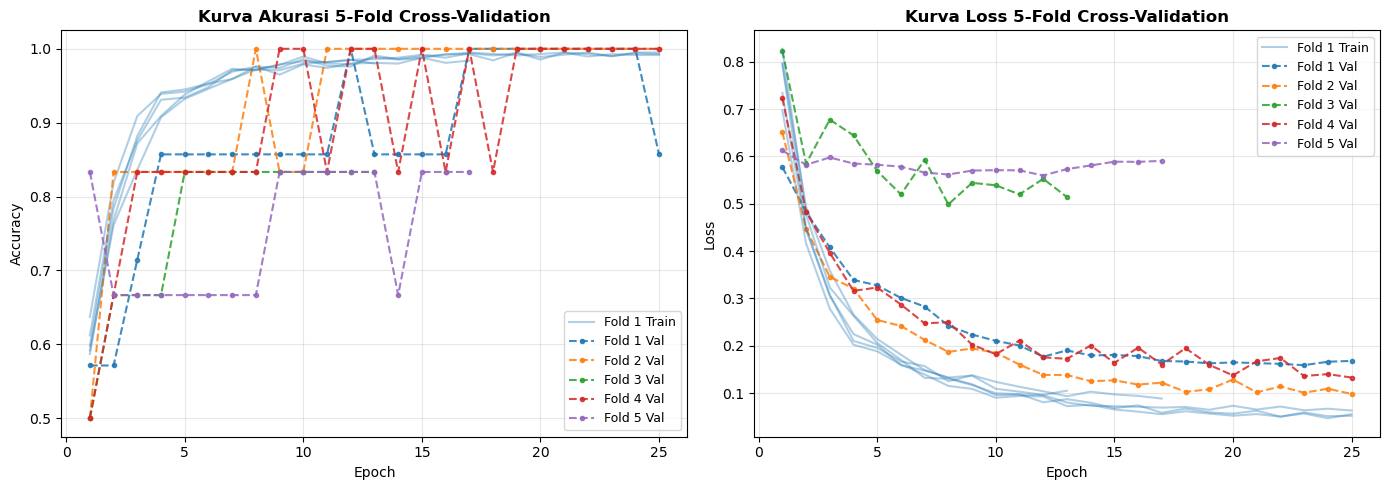

In [6]:
# 5.1 Kurva Belajar (Learning Curves) seluruh 5 Fold
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, hist in enumerate(fold_histories):
    epochs_range = range(1, len(hist["accuracy"]) + 1)
    axes[0].plot(epochs_range, hist["accuracy"], alpha=0.35, linestyle="-", label=f"Fold {i+1} Train" if i == 0 else None, color="#1f77b4")
    axes[0].plot(epochs_range, hist["val_accuracy"], alpha=0.85, linestyle="--", marker="o", markersize=3, label=f"Fold {i+1} Val")
    axes[1].plot(epochs_range, hist["loss"], alpha=0.35, linestyle="-", label=f"Fold {i+1} Train" if i == 0 else None, color="#1f77b4")
    axes[1].plot(epochs_range, hist["val_loss"], alpha=0.85, linestyle="--", marker="o", markersize=3, label=f"Fold {i+1} Val")

axes[0].set_title("Kurva Akurasi 5-Fold Cross-Validation", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="lower right", fontsize=9)

axes[1].set_title("Kurva Loss 5-Fold Cross-Validation", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

  LAPORAN EVALUASI AGREGAT FLOAT32 5-FOLD CV (Threshold Default: 0.50)
  Akurasi Agregat (31 Subjek)      : 90.32%
  Macro F1-Score Agregat           : 90.32%
  Balanced Accuracy                : 90.42%
  Sensitivity (Recall Male)        : 93.33%
  Specificity (Recall Female)      : 87.50%
  Matthews Correlation Coef. (MCC) : 0.8083

Detail Performa per Kelas (Float32):
              precision    recall  f1-score   support

      Female     0.9333    0.8750    0.9032        16
        Male     0.8750    0.9333    0.9032        15

    accuracy                         0.9032        31
   macro avg     0.9042    0.9042    0.9032        31
weighted avg     0.9051    0.9032    0.9032        31



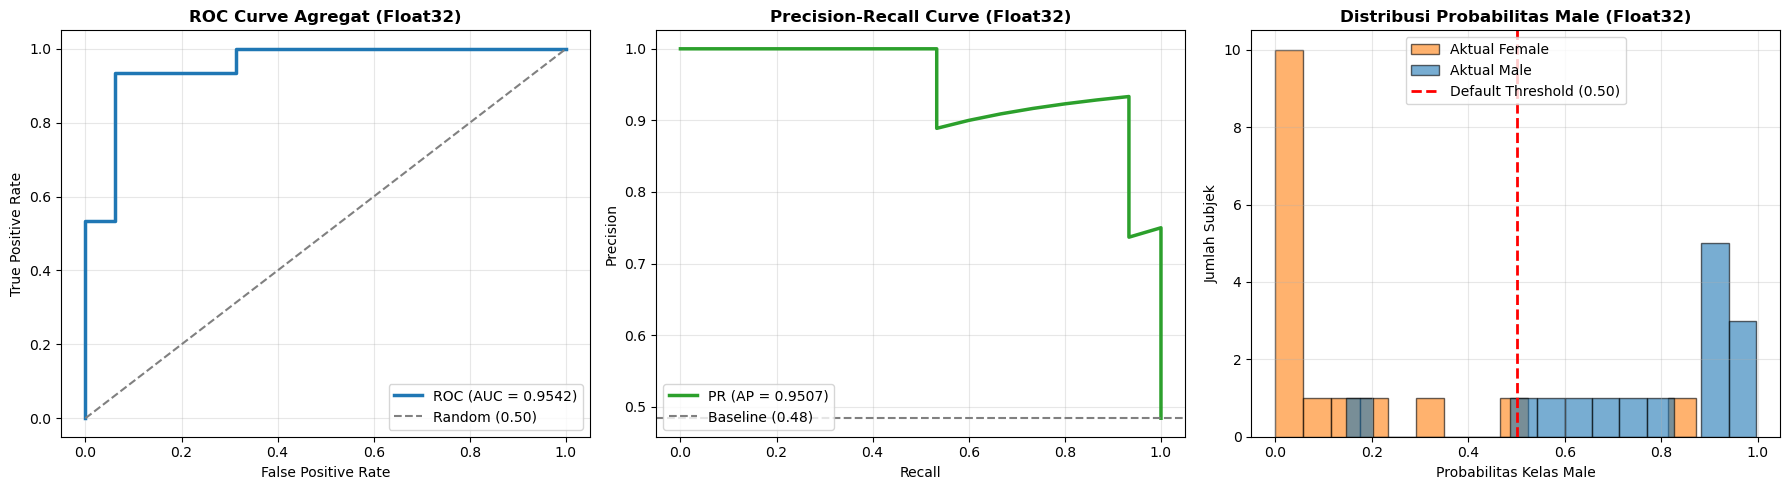

In [7]:
# 5.2 Evaluasi Agregat Float32 (31 Subjek, Default Threshold = 0.50)
acc_f32_agg = accuracy_score(all_val_trues, all_val_preds_f32) * 100.0
f1_f32_agg = f1_score(all_val_trues, all_val_preds_f32, average="macro") * 100.0
bal_acc_f32 = balanced_accuracy_score(all_val_trues, all_val_preds_f32) * 100.0
mcc_f32 = matthews_corrcoef(all_val_trues, all_val_preds_f32)

cm_f32 = confusion_matrix(all_val_trues, all_val_preds_f32)
tn_f32, fp_f32, fn_f32, tp_f32 = cm_f32.ravel()
sens_f32 = (tp_f32 / (tp_f32 + fn_f32)) * 100.0
spec_f32 = (tn_f32 / (tn_f32 + fp_f32)) * 100.0

print("=" * 75)
print(f"  LAPORAN EVALUASI AGREGAT FLOAT32 5-FOLD CV (Threshold Default: {DEFAULT_THRESHOLD:.2f})")
print("=" * 75)
print(f"  Akurasi Agregat (31 Subjek)      : {acc_f32_agg:.2f}%")
print(f"  Macro F1-Score Agregat           : {f1_f32_agg:.2f}%")
print(f"  Balanced Accuracy                : {bal_acc_f32:.2f}%")
print(f"  Sensitivity (Recall Male)        : {sens_f32:.2f}%")
print(f"  Specificity (Recall Female)      : {spec_f32:.2f}%")
print(f"  Matthews Correlation Coef. (MCC) : {mcc_f32:.4f}")
print("=" * 75)
print("\nDetail Performa per Kelas (Float32):")
print(classification_report(all_val_trues, all_val_preds_f32, target_names=CLASS_NAMES, digits=4))

# Kurva ROC & PR + Distribusi Probabilitas Float32
fpr_f32, tpr_f32, _ = roc_curve(all_val_trues, all_val_probs_f32[:, 1])
roc_auc_f32 = auc(fpr_f32, tpr_f32)
pr_prec_f32, pr_rec_f32, _ = precision_recall_curve(all_val_trues, all_val_probs_f32[:, 1])
pr_auc_f32 = average_precision_score(all_val_trues, all_val_probs_f32[:, 1])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(fpr_f32, tpr_f32, color="#1f77b4", lw=2.5, label=f"ROC (AUC = {roc_auc_f32:.4f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random (0.50)")
axes[0].set_title("ROC Curve Agregat (Float32)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

axes[1].plot(pr_rec_f32, pr_prec_f32, color="#2ca02c", lw=2.5, label=f"PR (AP = {pr_auc_f32:.4f})")
axes[1].axhline(y=np.mean(all_val_trues), color="gray", linestyle="--", label=f"Baseline ({np.mean(all_val_trues):.2f})")
axes[1].set_title("Precision-Recall Curve (Float32)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")
axes[1].grid(True, alpha=0.3)

probs_male_f32 = all_val_probs_f32[:, 1]
axes[2].hist(probs_male_f32[all_val_trues == 0], bins=15, alpha=0.6, color="#ff7f0e", label="Aktual Female", edgecolor="black")
axes[2].hist(probs_male_f32[all_val_trues == 1], bins=15, alpha=0.6, color="#1f77b4", label="Aktual Male", edgecolor="black")
axes[2].axvline(x=DEFAULT_THRESHOLD, color="red", linestyle="--", lw=2, label=f"Default Threshold ({DEFAULT_THRESHOLD:.2f})")
axes[2].set_title("Distribusi Probabilitas Male (Float32)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Probabilitas Kelas Male")
axes[2].set_ylabel("Jumlah Subjek")
axes[2].legend(loc="upper center")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Langkah 6: Explainability AI — Visualisasi Grad-CAM (Heatmap Atensi Sayap)
Memverifikasi area atensi layer konvolusi terakhir (`Conv_1` MobileNetV2) pada sampel uji fold terakhir.

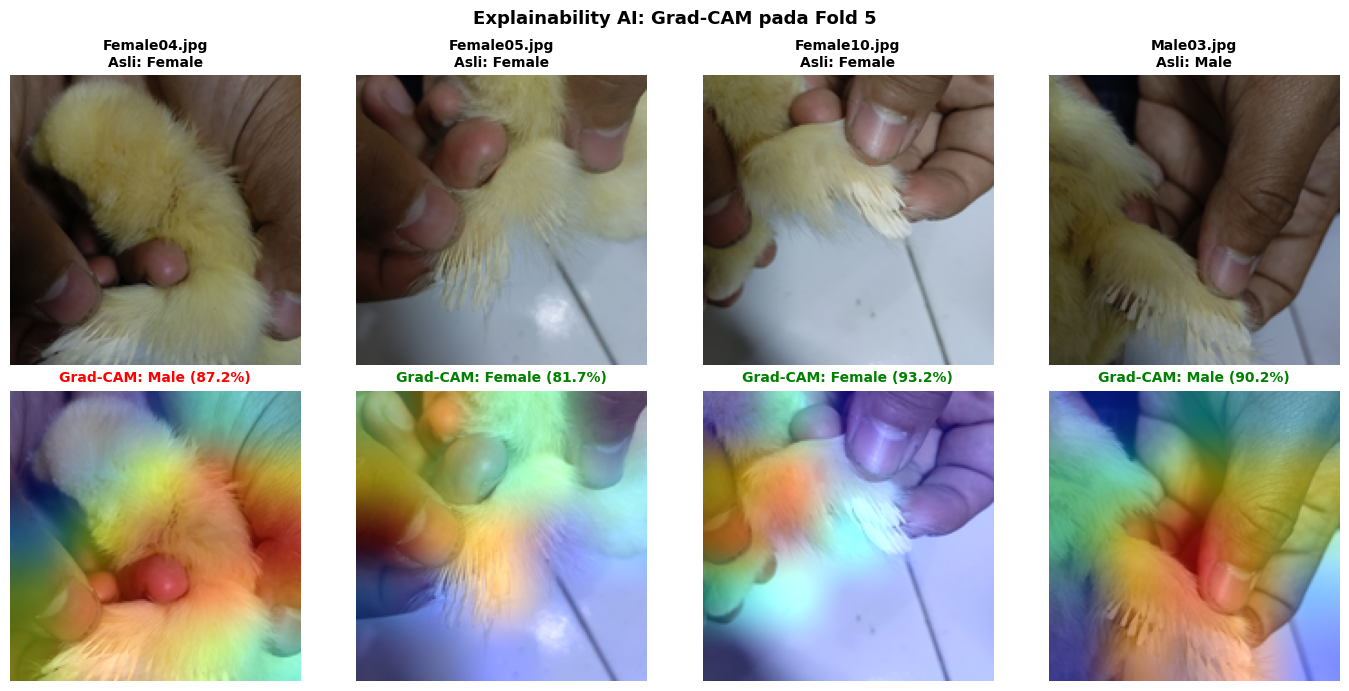

In [8]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name="Conv_1", pred_index=None):
    backbone = None
    for layer in model.layers:
        if isinstance(layer, tf.keras.Model) or "mobilenetv2" in layer.name.lower():
            backbone = layer
            break

    if backbone is not None:
        try:
            target_layer = backbone.get_layer(last_conv_layer_name)
        except Exception:
            conv_layers = [l for l in backbone.layers if "conv" in l.name.lower() or "relu" in l.name.lower()]
            target_layer = conv_layers[-1] if conv_layers else backbone.layers[-1]

        backbone_grad_model = tf.keras.models.Model([backbone.inputs], [target_layer.output])

        with tf.GradientTape() as tape:
            conv_output = backbone_grad_model(img_array)
            tape.watch(conv_output)
            x = model.get_layer("global_avg_pool")(conv_output)
            preds = model.get_layer("doc_classification_head")(x)
            if pred_index is None:
                pred_index = tf.argmax(preds[0])
            class_channel = preds[:, pred_index]

        grads = tape.gradient(class_channel, conv_output)
    else:
        target_layer = model.get_layer(last_conv_layer_name)
        grad_model = tf.keras.models.Model([model.inputs], [target_layer.output, model.output])
        with tf.GradientTape() as tape:
            conv_output, preds = grad_model(img_array)
            if pred_index is None:
                pred_index = tf.argmax(preds[0])
            class_channel = preds[:, pred_index]
        grads = tape.gradient(class_channel, conv_output)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0.0)
    max_val = tf.math.reduce_max(heatmap)
    if max_val > 0:
        heatmap = heatmap / max_val
    return heatmap.numpy()

n_show = min(4, len(last_fold_X_val))
plt.figure(figsize=(14, 7))
for i in range(n_show):
    img_tensor = tf.expand_dims(last_fold_X_val[i], axis=0)
    true_lbl = int(last_fold_y_val[i])
    pred_prob = last_fold_model.predict(img_tensor, verbose=0)[0]
    pred_lbl = int(pred_prob[1] >= DEFAULT_THRESHOLD)

    heatmap = make_gradcam_heatmap(img_tensor, last_fold_model, last_conv_layer_name="Conv_1")
    heatmap_resized = np.uint8(255 * heatmap)
    jet = plt.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = tf.keras.utils.array_to_img(jet_colors[heatmap_resized]).resize((IMG_SIZE, IMG_SIZE))
    jet_heatmap = tf.keras.utils.img_to_array(jet_heatmap)

    disp_img = ((last_fold_X_val[i] + 1.0) / 2.0) * 255.0
    superimposed = np.clip((jet_heatmap * 0.4 + disp_img) / 255.0, 0.0, 1.0)

    plt.subplot(2, n_show, i + 1)
    plt.imshow(np.clip((last_fold_X_val[i] + 1.0) / 2.0, 0.0, 1.0))
    plt.title(f"{last_fold_names[i]}\nAsli: {CLASS_NAMES[true_lbl]}", fontsize=10, fontweight="bold")
    plt.axis("off")

    plt.subplot(2, n_show, i + 1 + n_show)
    plt.imshow(superimposed)
    color = "green" if true_lbl == pred_lbl else "red"
    plt.title(f"Grad-CAM: {CLASS_NAMES[pred_lbl]} ({pred_prob[pred_lbl]*100:.1f}%)", fontsize=10, color=color, fontweight="bold")
    plt.axis("off")

plt.suptitle(f"Explainability AI: Grad-CAM pada Fold {N_SPLITS}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## Langkah 7: Evaluasi Komparasi Head-to-Head Model Float32 vs INT8 TFLite (5-Fold CV)
Membandingkan performa agregat seluruh 31 subjek, rata-rata per fold (Mean ± Std), ukuran model, dan *Accuracy Drop* antara **Float32** dan **INT8 TFLite** pada threshold default `0.50`.

  EVALUASI AGREGAT INT8 TFLITE 5-FOLD CV (Threshold Default: 0.50)
  Akurasi Agregat INT8 (31 Subjek) : 83.87%
  Macro F1-Score INT8              : 83.60%
  Accuracy Drop Agregat (F32-INT8) : +6.45%
              precision    recall  f1-score   support

      Female     0.7895    0.9375    0.8571        16
        Male     0.9167    0.7333    0.8148        15

    accuracy                         0.8387        31
   macro avg     0.8531    0.8354    0.8360        31
weighted avg     0.8510    0.8387    0.8367        31


  TABEL KOMPARASI HEAD-TO-HEAD: FLOAT32 vs INT8 TFLITE (5-FOLD CV)
  Parameter / Metrik                 | Float32 Model      | INT8 TFLite NPU   
  --------------------------------------------------------------------------
  Mean CV Accuracy (5-Fold)          |  90.48% ±  7.82%  |  83.81% ± 10.58%
  Mean CV Macro F1 (5-Fold)          |  90.29% ±  8.00%  |  83.37% ± 10.56%
  Aggregate Accuracy (31 Subjek)     |            90.32% |            83.87%
  Aggregate Macro F1 

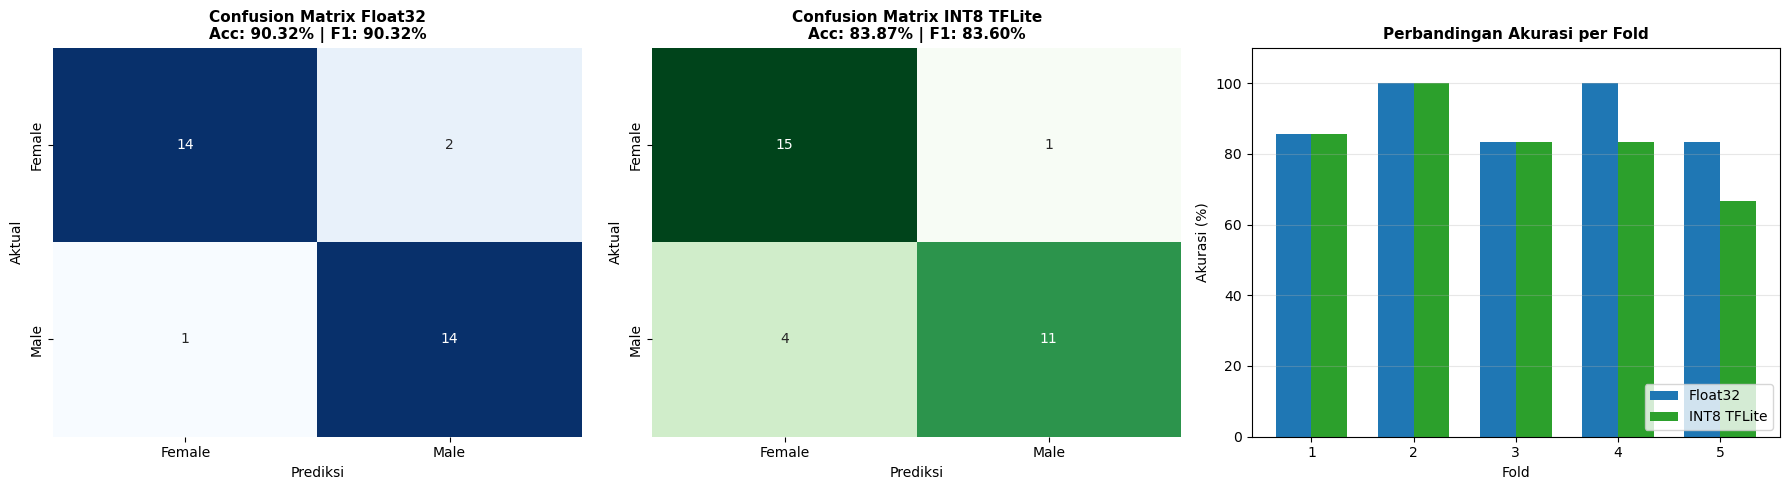

In [9]:
accs_f32 = np.array([m[0] for m in fold_metrics_f32]) * 100.0
f1s_f32 = np.array([m[1] for m in fold_metrics_f32]) * 100.0
accs_int8 = np.array([m[0] for m in fold_metrics_int8]) * 100.0
f1s_int8 = np.array([m[1] for m in fold_metrics_int8]) * 100.0

acc_int8_agg = accuracy_score(all_val_trues, all_val_preds_int8) * 100.0
f1_int8_agg = f1_score(all_val_trues, all_val_preds_int8, average="macro") * 100.0
bal_acc_int8 = balanced_accuracy_score(all_val_trues, all_val_preds_int8) * 100.0
mcc_int8 = matthews_corrcoef(all_val_trues, all_val_preds_int8)

cm_int8 = confusion_matrix(all_val_trues, all_val_preds_int8)
tn_i8, fp_i8, fn_i8, tp_i8 = cm_int8.ravel()
sens_int8 = (tp_i8 / (tp_i8 + fn_i8)) * 100.0
spec_int8 = (tn_i8 / (tn_i8 + fp_i8)) * 100.0

avg_size_f32 = np.mean(fold_sizes_f32_kb)
avg_size_int8 = np.mean(fold_sizes_int8_kb)
compression_ratio = avg_size_f32 / avg_size_int8

mean_drop_acc = np.mean(accs_f32) - np.mean(accs_int8)
agg_drop_acc = acc_f32_agg - acc_int8_agg

print("=" * 78)
print(f"  EVALUASI AGREGAT INT8 TFLITE 5-FOLD CV (Threshold Default: {DEFAULT_THRESHOLD:.2f})")
print("=" * 78)
print(f"  Akurasi Agregat INT8 (31 Subjek) : {acc_int8_agg:.2f}%")
print(f"  Macro F1-Score INT8              : {f1_int8_agg:.2f}%")
print(f"  Accuracy Drop Agregat (F32-INT8) : {agg_drop_acc:+.2f}%")
print("=" * 78)
print(classification_report(all_val_trues, all_val_preds_int8, target_names=CLASS_NAMES, digits=4))

print("\n" + "=" * 78)
print("  TABEL KOMPARASI HEAD-TO-HEAD: FLOAT32 vs INT8 TFLITE (5-FOLD CV)")
print("=" * 78)
print(f"  {'Parameter / Metrik':<34} | {'Float32 Model':<18} | {'INT8 TFLite NPU':<18}")
print("  " + "-" * 74)
print(f"  {'Mean CV Accuracy (5-Fold)':<34} | {np.mean(accs_f32):6.2f}% ± {np.std(accs_f32):5.2f}%  | {np.mean(accs_int8):6.2f}% ± {np.std(accs_int8):5.2f}%")
print(f"  {'Mean CV Macro F1 (5-Fold)':<34} | {np.mean(f1s_f32):6.2f}% ± {np.std(f1s_f32):5.2f}%  | {np.mean(f1s_int8):6.2f}% ± {np.std(f1s_int8):5.2f}%")
print(f"  {'Aggregate Accuracy (31 Subjek)':<34} | {acc_f32_agg:>16.2f}% | {acc_int8_agg:>16.2f}%")
print(f"  {'Aggregate Macro F1 (31 Subjek)':<34} | {f1_f32_agg:>16.2f}% | {f1_int8_agg:>16.2f}%")
print(f"  {'Balanced Accuracy':<34} | {bal_acc_f32:>16.2f}% | {bal_acc_int8:>16.2f}%")
print(f"  {'Sensitivity (Recall Male)':<34} | {sens_f32:>16.2f}% | {sens_int8:>16.2f}%")
print(f"  {'Specificity (Recall Female)':<34} | {spec_f32:>16.2f}% | {spec_int8:>16.2f}%")
print(f"  {'Matthews Correlation Coef. (MCC)':<34} | {mcc_f32:>17.4f} | {mcc_int8:>17.4f}")
print(f"  {'Rata-rata Ukuran File':<34} | {avg_size_f32:>13.1f} KB | {avg_size_int8:>13.1f} KB")
print(f"  {'Rasio Kompresi':<34} | {'1.00x (Baseline)':>18} | {compression_ratio:>15.2f}x")
print(f"  {'Accuracy Drop (Mean CV / Agg)':<34} | {'-':>18} | {mean_drop_acc:+.2f}% / {agg_drop_acc:+.2f}%")
print("=" * 78)

# Visualisasi Perbandingan Confusion Matrix & Akurasi Per Fold
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(cm_f32, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=axes[0])
axes[0].set_title(f"Confusion Matrix Float32\nAcc: {acc_f32_agg:.2f}% | F1: {f1_f32_agg:.2f}%", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")

sns.heatmap(cm_int8, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=axes[1])
axes[1].set_title(f"Confusion Matrix INT8 TFLite\nAcc: {acc_int8_agg:.2f}% | F1: {f1_int8_agg:.2f}%", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Aktual")

x_pos = np.arange(1, N_SPLITS + 1)
width = 0.35
axes[2].bar(x_pos - width/2, accs_f32, width, label="Float32", color="#1f77b4")
axes[2].bar(x_pos + width/2, accs_int8, width, label="INT8 TFLite", color="#2ca02c")
axes[2].set_title("Perbandingan Akurasi per Fold", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Fold")
axes[2].set_ylabel("Akurasi (%)")
axes[2].set_xticks(x_pos)
axes[2].set_ylim(0, 110)
axes[2].legend(loc="lower right")
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Langkah 8: Training Final Model (100% Data = 31 Subjek) & Konversi INT8 TFLite
Setelah performa metode tervalidasi melalui 5-Fold CV, seluruh **31 subjek** (16 Female, 15 Male) digunakan untuk melatih **1 Final Model** dengan jumlah epoch optimal rata-rata dari hasil CV (`argmin(val_loss) + 1`), lalu langsung dikonversi ke **INT8 TFLite** menggunakan *representative dataset* citra asli (Metode 1).


In [10]:
# 8.1 Hitung epoch optimal rata-rata dari 5-Fold CV
best_epochs_per_fold = [int(np.argmin(h["val_loss"]) + 1) for h in fold_histories]
FINAL_EPOCHS = max(10, int(np.round(np.mean(best_epochs_per_fold))))
print(f"Best epochs per fold : {best_epochs_per_fold} -> FINAL_EPOCHS = {FINAL_EPOCHS}")

# 8.2 Siapkan 100% data latih (31 subjek x 40 sampel = 1.240 citra)
all_indices = np.arange(len(subjects_images))
X_all_tr, y_all_tr, _, _ = generate_fold_data(
    all_indices, [], samples_per_train_subject=SAMPLES_PER_TRAIN_SUBJECT
)

classes_unique_all = np.unique(y_all_tr)
weights_all = compute_class_weight(class_weight="balanced", classes=classes_unique_all, y=y_all_tr)
class_weights_all = {int(c): float(w) for c, w in zip(classes_unique_all, weights_all)}

tf.keras.backend.clear_session()
final_model = build_npu_mobilenetv2_doc(verbose=True)

final_callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1
    )
]

print(f"\n=== MELATIH FINAL MODEL PADA 100% DATA ({len(X_all_tr)} citra, {FINAL_EPOCHS} epoch) ===")
final_history = final_model.fit(
    X_all_tr, y_all_tr,
    epochs=FINAL_EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights_all,
    callbacks=final_callbacks,
    verbose=1,
)

# 8.3 Simpan Final Model Float32
final_keras_path = MODEL_OUTPUT_DIR / "mobilenetv2_doc_final_float32.keras"
final_model.save(final_keras_path)
final_f32_kb = os.path.getsize(final_keras_path) / 1024.0
print(f"\n[SUCCESS] Final Float32 Model : {final_keras_path.resolve()} ({final_f32_kb:.1f} KB)")

# 8.4 Konversi Final Model ke INT8 TFLite (Metode 1: Representative Dataset Citra Asli + Flip)
X_rep_final_clean = []
X_all_raw = []
for idx in all_indices:
    base_img = subjects_images[idx]
    arr_orig = np.array(base_img, dtype=np.float32) / 127.5 - 1.0
    arr_flip = np.array(base_img.transpose(Image.FLIP_LEFT_RIGHT), dtype=np.float32) / 127.5 - 1.0
    X_all_raw.append(arr_orig)
    X_rep_final_clean.append(arr_orig)
    X_rep_final_clean.append(arr_flip)

X_all_raw = np.array(X_all_raw, dtype=np.float32)
X_rep_final_clean = np.array(X_rep_final_clean, dtype=np.float32)

final_tflite_path = MODEL_OUTPUT_DIR / "model_doc_final_int8.tflite"
final_int8_kb = convert_fold_to_int8_tflite(final_model, X_rep_final_clean, final_tflite_path)

labels_final_path = MODEL_OUTPUT_DIR / "labels_doc.txt"
with open(labels_final_path, "w") as f:
    for i, name in enumerate(CLASS_NAMES):
        f.write(f"{i} {name}\n")

print(f"[SUCCESS] Final INT8 TFLite   : {final_tflite_path.resolve()} ({final_int8_kb:.1f} KB)")
print(f"[SUCCESS] Labels File         : {labels_final_path.resolve()}")

# 8.5 Sanity Check Konsistensi Final Float32 vs Final INT8 pada 31 Citra Asli
# (Catatan: ini pengecekan in-sample untuk verifikasi kuantisasi; metrik generalisasi ada pada Langkah 4-7)
probs_final_f32 = final_model.predict(X_all_raw, verbose=0)
preds_final_f32 = (probs_final_f32[:, 1] >= DEFAULT_THRESHOLD).astype(int)

probs_final_int8 = evaluate_int8_tflite(final_tflite_path, X_all_raw)
preds_final_int8 = (probs_final_int8[:, 1] >= DEFAULT_THRESHOLD).astype(int)

acc_in_f32 = accuracy_score(subjects_labels, preds_final_f32) * 100.0
acc_in_int8 = accuracy_score(subjects_labels, preds_final_int8) * 100.0
agreement = np.mean(preds_final_f32 == preds_final_int8) * 100.0

print("\n" + "=" * 75)
print("  SANITY CHECK FINAL MODEL (IN-SAMPLE 31 CITRA ASLI): FLOAT32 vs INT8")
print("=" * 75)
print(f"  In-Sample Acc Float32    : {acc_in_f32:.2f}%")
print(f"  In-Sample Acc INT8       : {acc_in_int8:.2f}%")
print(f"  Agreement F32 vs INT8    : {agreement:.2f}%")
print(f"  Ukuran File (F32 / INT8) : {final_f32_kb:.1f} KB -> {final_int8_kb:.1f} KB ({final_f32_kb / final_int8_kb:.2f}x)")
print("=" * 75)

Best epochs per fold : [23, 25, 8, 25, 12] -> FINAL_EPOCHS = 19

=== MELATIH FINAL MODEL PADA 100% DATA (1240 citra, 19 epoch) ===
Epoch 1/19
78/78 [==============================] - 6s 33ms/step - loss: 0.8608 - accuracy: 0.5355 - lr: 5.0000e-04
Epoch 2/19
78/78 [==============================] - 2s 30ms/step - loss: 0.4616 - accuracy: 0.7806 - lr: 5.0000e-04
Epoch 3/19
78/78 [==============================] - 3s 33ms/step - loss: 0.3206 - accuracy: 0.8790 - lr: 5.0000e-04
Epoch 4/19
78/78 [==============================] - 3s 34ms/step - loss: 0.2397 - accuracy: 0.9185 - lr: 5.0000e-04
Epoch 5/19
78/78 [==============================] - 2s 32ms/step - loss: 0.1779 - accuracy: 0.9581 - lr: 5.0000e-04
Epoch 6/19
78/78 [==============================] - 2s 31ms/step - loss: 0.1610 - accuracy: 0.9548 - lr: 5.0000e-04
Epoch 7/19
78/78 [==============================] - 2s 31ms/step - loss: 0.1431 - accuracy: 0.9685 - lr: 5.0000e-04
Epoch 8/19
78/78 [==============================] - 3s 36

2026-11-25 18:10:15.345240: I tensorflow/core/grappler/devices.cc:66] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
2026-11-25 18:10:15.345711: I tensorflow/core/grappler/clusters/single_machine.cc:361] Starting new session
/home/nexus_is/miniconda3/envs/ml/lib/python3.10/site-packages/tensorflow/lite/python/convert.py:953: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
2026-11-25 18:10:15.845771: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:378] Ignored output_format.
2026-11-25 18:10:15.845798: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:381] Ignored drop_control_dependency.
Summary on the non-converted ops:
---------------------------------
 * Accepted dialects: tfl, builtin, func
 * Non-Converted Ops: 108, Total Ops 180, % non-converted = 60.00 %
 * 108 ARITH ops

- arith.constant:  108 occurrences  (f32: 106, i32: 2)



  (f32: 10)
  (f32: 35

[SUCCESS] Final INT8 TFLite   : /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2/model/model_doc_final_int8.tflite (612.3 KB)
[SUCCESS] Labels File         : /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2/model/labels_doc.txt



  SANITY CHECK FINAL MODEL (IN-SAMPLE 31 CITRA ASLI): FLOAT32 vs INT8
  In-Sample Acc Float32    : 100.00%
  In-Sample Acc INT8       : 100.00%
  Agreement F32 vs INT8    : 100.00%
  Ukuran File (F32 / INT8) : 2149.0 KB -> 612.3 KB (3.51x)


## Langkah 9: Panduan Kompilasi Arm Ethos-U55 Vela NPU
Final model INT8 tersimpan di `PP2/model/model_doc_final_int8.tflite`. Untuk mengompilasi ke format biner NPU Grove Vision AI V2:

```bash
cd PP2/model
vela model_doc_final_int8.tflite --accelerator-config ethos-u55-64 --output-dir ./vela_out
```
